## Physics-Motivated Geometric Representation for Propagation-State Prediction in 3D UAV Communication Environments

## Performance Evaluation

This notebook reproduces the experiments used to evaluate the proposed physics-motivated geometric representation for propagation-state prediction.

The notebook contains the following evaluation components:

Within-scenario representation comparison
The proposed representation is compared with the considered geometry-based baselines using an identical XGBoost classifier and transmitter-level train–test partitioning.

Analytical and standardized baseline comparison
Distance-based, height-distance, and 3GPP TR 38.901 representations are evaluated to quantify the additional predictive information provided by the proposed geometry-aware descriptors.

Cross-environment evaluation
The learned representation is evaluated under domain shifts between different urban environments and deployment configurations.

Leave-one-environment-out evaluation
Complete environments are held out from training to assess generalization to previously unseen environments.

Trajectory-based evaluation
The trained model is applied to UAV trajectory points from an unseen environment to evaluate propagation-state prediction along a mobile communication link.

Ablation analysis
Individual descriptor families and their incremental combinations are evaluated to quantify their predictive contribution.

Interpretability analysis
SHAP-based analysis is used to investigate the contribution of individual descriptors and descriptor families to the classifier decisions.


Reproducibility

All experiments use fixed random seeds where applicable. Transmitter-level grouping is used for data partitioning to prevent links associated with the same transmitter from appearing in both training and testing sets.

The notebook assumes that the required datasets have been downloaded and that the paths defined in the configuration cells point to the corresponding scenario files. The feature definitions, scenario configuration, output directories, and required Python packages should be defined in the preceding setup notebooks or configuration cells.



# 1. Imports

In [1]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)

from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

import ezdxf

import pandas as pd
import numpy as np

from pathlib import Path

import shap

##  Feature Definitions
 The following feature sets are evaluated in the experiments.

 - `features1`: Physics-motivated geometric representation proposed in this work.
 - `features2`: Geometric baseline based on Hussain et al.
 - `features3`: Geometric baseline based on Ladan et al.

 The feature names correspond to columns in the preprocessed feature datasets.

In [2]:
features1 = [
    ####### 3D Link Geometry Features  ###############
    "distance_3d",  
    "elevation_angle_deg",   
    "tx_height",  
    "rx_height",   
    ###### LOS Blockage Geometry Features  ###############
    "blocking_Candidate_number", 
    "blocking_score", 
    "blocking_position", 
    "blocking_alignment", 
    "blocking_margin", 
    "blocking_Delta_height", 
    ######################  Geometric Multipath Environment Features  ###########    
    "blocker_count",    
    "sum_blocker",  
    "occupancy",  
    "blocking_potential", 
    "reflection_potential",  
    "effective_reflect_area", 
    "log_reflection_ratio", 
    #################   Local Spatial Confinement Features  ############    
    "local_confinement", 
    "normalize_local_confinement", 
]

features2 = [
    "3d_distance",
    "Transmitte_ZZ",
    "Theta",
    "Phi",
    "Wall_pen",
    "indoor_distance",
    "outdoor_distance",
    "no_visible_walls",
    "min_distance_to_walls",
    "avg_distance_to_walls",
    "min_wall_height",
    "max_wall_height",
    "avg_wall_height"
]

features3 = [
    "3D_Distance",
    "Num_buildings",
    "Maximum_height",
    "Minimum_height",
    "Average_height",
    "Median_Height",
    "Density_Ratio",
    "Num_building_above_avg",
    "Num_faces",
    "Num_vertices"    
]

##########################

feature_sets = {

    "Distance-only": [
        "distance_3d"
    ],

    "Height-distance": [
        "distance_3d",
        "tx_height",
        "rx_height"
    ],

    "Proposed": [

        "distance_3d",
        "elevation_angle_deg",
        "tx_height",
        "rx_height",

        "blocking_Candidate_number",
        "blocking_score",
        "blocking_position",
        "blocking_alignment",
        "blocking_margin",
        "blocking_Delta_height",

        "blocker_count",
        "sum_blocker",
        "occupancy",
        "blocking_potential",
        "reflection_potential",
        "effective_reflect_area",
        "log_reflection_ratio",

        "local_confinement",
        "normalize_local_confinement",
    ]
}
feature_groups = {

    r"$\Phi_L$": [
        "distance_3d",
        "elevation_angle_deg",
        "tx_height",
        "rx_height",
    ],

    r"$\Phi_B$": [
        "blocking_Candidate_number",
        "blocking_score",
        "blocking_position",
        "blocking_alignment",
        "blocking_margin",
        "blocking_Delta_height",
    ],

    r"$\Phi_M$": [
        "blocker_count",
        "sum_blocker",
        "occupancy",
        "blocking_potential",
        "reflection_potential",
        "effective_reflect_area",
        "log_reflection_ratio",
    ],

    r"$\Phi_C$": [
        "local_confinement",
        "normalize_local_confinement",
    ],
}


incremental_features = {

    r"$F_1$":

        feature_groups[r"$\Phi_L$"],


    r"$F_2$":

        feature_groups[r"$\Phi_L$"] +
        feature_groups[r"$\Phi_B$"],


    r"$F_3$":

        feature_groups[r"$\Phi_L$"] +
        feature_groups[r"$\Phi_B$"] +
        feature_groups[r"$\Phi_M$"],


    r"$F_4$":

        feature_groups[r"$\Phi_L$"] +
        feature_groups[r"$\Phi_B$"] +
        feature_groups[r"$\Phi_M$"] +
        feature_groups[r"$\Phi_C$"]

}





##  Experiment Configuration
This section defines the main parameters used for the experiments.

In [3]:
BASE_DIR = Path(".")
REPRESENTATION_DIR = BASE_DIR / "REPRESENTATION_DIR"
OUTPUT_DIR1 = BASE_DIR / "OUTPUT_DIR" / "Comparison_With_Others.csv"
OUTPUT_DIR2 = BASE_DIR / "OUTPUT_DIR" / "Comparison_With_Analytical.csv"
OUTPUT_DIR3 = BASE_DIR / "OUTPUT_DIR" / "Leave-One-Environment-Out.csv"
OUTPUT_DIR3_1 = BASE_DIR / "OUTPUT_DIR" / "Classification_Performance_Heatmap.png"
OUTPUT_DIR3_2 = BASE_DIR / "OUTPUT_DIR" / "Classification_Performance_Heatmap.pdf"
OUTPUT_DIR4 = BASE_DIR / "OUTPUT_DIR" / "CrossScenarioFeature-space_overlap.pdf"
OUTPUT_DIR5 = BASE_DIR / "OUTPUT_DIR" / "CrossScenarioFeature-space_overlap.png"
OUTPUT_DIR6 = BASE_DIR / "OUTPUT_DIR" / "ABLATION-Individual.csv"
OUTPUT_DIR7 = BASE_DIR / "OUTPUT_DIR" / "ABLATION-Incremental.csv"
OUTPUT_DIR8 = BASE_DIR / "OUTPUT_DIR" / "Global_SHAP_Importance.csv"
OUTPUT_DIR9 = BASE_DIR / "OUTPUT_DIR"



In [4]:

scenarios = {
    1: {
        "name":"Seoul",
        "Our_geo": REPRESENTATION_DIR / "Seoul_Our_features.csv", #Our1_features_LOS
        "Hussein_geo": REPRESENTATION_DIR / "Seoul_Hussein_Features.csv",
        "Ladan_geo": REPRESENTATION_DIR / "Seoul_Ladan_features.csv",
        "link": REPRESENTATION_DIR / "Seoul_South Korea_LinkLevel.csv"
    },
    2: {
        "name":"Boston",
        "Our_geo": REPRESENTATION_DIR / "Boston_Our_features.csv", #_Our1_features_LOS
        "Hussein_geo": REPRESENTATION_DIR / "Boston_Hussein_Features.csv",
        "Ladan_geo": REPRESENTATION_DIR / "Boston_Ladan_features.csv",
        "link": REPRESENTATION_DIR / "Boston_LinkLevel.csv"
    },
    3: {
        "name":"Pisa East",
        "Our_geo": REPRESENTATION_DIR / "Pisa_East_Our_features.csv", #_Our1_features_LOS
        "Hussein_geo": REPRESENTATION_DIR / "Pisa_East_Hussein_Features.csv",
        "Ladan_geo": REPRESENTATION_DIR / "Pisa_East_Ladan_features.csv",
        "link": REPRESENTATION_DIR / "Pisa_East_LinkLevel.csv"
    },
    4: {
        "name":"Pisa West",
        "Our_geo": REPRESENTATION_DIR / "Pisa_West_Our_features.csv", #_Our1_features_LOS
        "Hussein_geo":  REPRESENTATION_DIR / "Pisa_West_Hussein_Features.csv",
        "Ladan_geo": REPRESENTATION_DIR / "Pisa_West_Ladan_features.csv",
        "link": REPRESENTATION_DIR / "Pisa_West_LinkLevel.csv"
    },
    5: {
        "name":"London",
        "Our_geo": REPRESENTATION_DIR / "London_Our_features.csv", #_Our1_features_LOS
        "Hussein_geo": REPRESENTATION_DIR / "London_Hussein_Features.csv",
        "Ladan_geo": REPRESENTATION_DIR / "London_Ladan_Features.csv",
        "link": REPRESENTATION_DIR / "London_LinkLevel.csv"
    },
    6: {
        "name":"Manhattan",
        "Our_geo": REPRESENTATION_DIR / "Manhattan_Our_features.csv", #_Our1_features_LOS
        "Hussein_geo": REPRESENTATION_DIR / "Manhattan_Hussein_Features.csv",
        "Ladan_geo": REPRESENTATION_DIR / "Manhattan_Ladan_features.csv",
        "link": REPRESENTATION_DIR / "Manhattan_LinkLevel.csv"
    }
}



## Experiment: Within-Scenario Comparison of Geometric Representations - Comparison With Existing Approaches

This experiment evaluates the predictive effectiveness of different geometric representations for propagation-state classification. The compared representations are evaluated using the same transmitter–receiver links, propagation-state labels, classifier architecture, train–test partitioning strategy, and evaluation metrics. Only the input geometric feature representation is changed between experiments.

For each scenario, the corresponding geometric feature file is merged with the communication-link file using the transmitter (TX) and receiver (RX) identifiers. The propagation state (Status) is used as the supervised target variable, while TX is used as the grouping variable for train–test partitioning.

Three geometric representations are evaluated:

Ours: the proposed physics-motivated geometric descriptors.
Hussein: the geometry-based feature representation described in the corresponding baseline study.
Ladan: the urban-morphology/statistical feature representation described in the corresponding baseline study.

The purpose of this experiment is to isolate the effect of the geometric representation while keeping the learning algorithm and training protocol fixed.

In [ ]:

def evaluate_feature_set(name,City_name,geo_file,link_file,features,results):
    """
    Train and evaluate an XGBoost propagation-state classifier for one
    geometric representation and one scenario.

    Parameters
    ----------
    name : str
        Name of the geometric representation being evaluated.
    City_name : str
        Scenario identifier used to label the output results.
    geo_file : str
        Path to the CSV file containing geometry-derived descriptors.
    link_file : str
        Path to the CSV file containing TX/RX link information and
        propagation-state labels.
    features : list of str
        Names of the geometric descriptors used as model inputs.
    results : list of dict
        Accumulator containing results from previously evaluated
        representation/scenario combinations.

    Returns
    -------
    xgb : XGBClassifier
        Trained XGBoost classifier.
    results : list of dict
        Updated list containing class-wise and aggregate evaluation
        metrics for the current representation and scenario.

    Notes
    -----
    The geometry and communication data are joined using the TX/RX pair.
    Samples are grouped by transmitter and partitioned using
    GroupShuffleSplit with 20% of transmitters assigned to the test set.
    Class-balanced sample weights are used during training.

    The classifier uses a fixed XGBoost configuration so that differences
    in performance are attributable to the input geometric representation
    rather than representation-specific classifier tuning.
    """
    link_df = pd.read_csv(link_file)
    geo_df = pd.read_csv(geo_file)
    df = pd.merge(geo_df,link_df[["TX","RX","Status","Received_Power_dBm"]],on=["TX","RX"],how="inner")    
    X = df[features]
    y = df["Status"]
    groups = df["TX"]
    splitter = GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
    train_idx,test_idx = next(splitter.split(X,y,groups))
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]    
    sample_weights = compute_sample_weight(class_weight="balanced",y=y_train)
    xgb = XGBClassifier(n_estimators=800,max_depth=10,learning_rate=0.05,subsample=0.9,
                        colsample_bytree=0.9,objective="multi:softmax",num_class=3,n_jobs=-1,random_state=42)    
    xgb.fit(X_train,y_train,sample_weight=sample_weights)    
    y_pred_xgb = xgb.predict(X_test)    
    report_s1 = classification_report(y_test,y_pred_xgb,output_dict=True)
    results.append({
        "Representation": name,
        "Scenario": City_name,
        "Blocked_precision":report_s1["0"]["precision"],
        "Blocked_recall":report_s1["0"]["recall"],
        "Blocked_f1-score":report_s1["0"]["f1-score"],
        "LOS_precision":report_s1["1"]["precision"],
        "LOS_recall":report_s1["1"]["recall"],
        "LOS_f1-score":report_s1["1"]["f1-score"],
        "NLOS_precision":report_s1["2"]["precision"],  
        "NLOS_recall":report_s1["2"]["recall"],
        "NLOS_f1-score":report_s1["2"]["f1-score"],
        "accuracy": accuracy_score(y_test, y_pred_xgb),
        "macro_precision": report_s1["macro avg"]["precision"],
        "macro_recall": report_s1["macro avg"]["recall"],
        "macro_f1": report_s1["macro avg"]["f1-score"]
    })    
    return xgb, results

# Evaluate each geometric representation independently for every scenario.
#
# For each scenario, the same TX/RX communication links are combined with
# three alternative geometric feature representations. The classifier
# configuration and transmitter-level train/test protocol remain unchanged;
# only the input feature set is modified.
#
# The resulting metrics are accumulated in `results` and exported as a CSV
# table for subsequent analysis and paper tables/figures.
results = []    
for idx, scenario in scenarios.items():   
    name = scenario["name"]
    geo_file1 = scenario["Our_geo"]
    geo_file2 = scenario["Hussein_geo"]
    geo_file3 = scenario["Ladan_geo"]
    link_file = scenario["link"] 
    
    model1, results = evaluate_feature_set("Ours",name,geo_file1,link_file, features1, results)
    model2, results = evaluate_feature_set("Hussein",name,geo_file2,link_file, features2, results)
    model3, results = evaluate_feature_set("Ladan",name,geo_file3,link_file, features3, results)

results = pd.DataFrame(results)
results.to_csv(OUTPUT_DIR1,index=False)


## Comparison With Analytical and Standardized Propagation Models

In [ ]:

def model_3GPP_38901(df):
    """
    Compute deterministic LOS/NLOS predictions using the 3GPP TR 38.901
    Urban Macro (UMa) LOS probability model.

    The LOS probability is computed from the 3D TX-RX distance. A probability
    greater than 0.5 is classified as LOS; otherwise the link is classified
    as NLOS.

    The standardized model does not define a separate Blocked class.
    Therefore, the Blocked state is not explicitly predicted by this
    analytical baseline and is treated as NLOS when compared with the
    three-class ground-truth labels.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing the `distance_3d` column.

    Returns
    -------
    numpy.ndarray
        Predicted propagation states using the class encoding:
        1 = LOS, 2 = NLOS.
    """

    d = df["distance_3d"].to_numpy()
    PLOS = (np.minimum(18.0 / d, 1.0)* (1.0 - np.exp(-d / 63.0))+ np.exp(-d / 63.0))
    pred = np.where(PLOS > 0.5, 1, 2)
    return pred

def evaluate_3gpp(df):
    X = df[["distance_3d"]]
    y = df["Status"]
    groups = df["TX"]
    splitter = GroupShuffleSplit(n_splits=10,test_size=0.20,random_state=42)
    results = []
    for _, test_idx in splitter.split(X, y, groups):
        test_df = df.iloc[test_idx]
        y_test = test_df["Status"]
        pred = model_3GPP_38901(test_df)
        results.append({
            "Accuracy":accuracy_score(y_test, pred),
            "Precision":precision_score(y_test,pred,average="macro",zero_division=0),
            "Recall":recall_score(y_test,pred,average="macro",zero_division=0),
            "F1":f1_score(y_test,pred,average="macro",zero_division=0)
        })
    return pd.DataFrame(results).mean()

def evaluate_feature_set_repeated(df, features):
    """
    Evaluate one geometric feature representation using repeated
    transmitter-level train/test partitions.

    Parameters
    ----------
    df : pandas.DataFrame
        Merged dataset containing geometric descriptors, TX identifiers,
        and propagation-state labels.
    features : list of str
        Names of the descriptors supplied to the classifier.

    Returns
    -------
    pandas.Series
        Mean accuracy, macro precision, macro recall, and macro F1-score
        over the generated transmitter-level train/test partitions.

    Notes
    -----
    Each partition is generated using GroupShuffleSplit with TX as the
    grouping variable and a 20% test-group fraction. A new XGBoost model
    is trained independently for each partition.

    Class-balanced sample weights are computed from the training labels
    only and are not applied to the test data.
    """
    X = df[features]
    y = df["Status"]
    groups = df["TX"]
    splitter = GroupShuffleSplit(n_splits=10,test_size=0.20,random_state=42)
    results = []
    for train_idx, test_idx in splitter.split(X, y, groups):
        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]
        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]
        sample_weights = compute_sample_weight(class_weight="balanced",y=y_train)
        model = XGBClassifier(n_estimators=800,max_depth=10,learning_rate=0.05,subsample=0.9,colsample_bytree=0.9,
            objective="multi:softmax",num_class=len(np.unique(y_train)),random_state=42,n_jobs=-1)
        model.fit(X_train,y_train,sample_weight=sample_weights)
        pred = model.predict(X_test)
        results.append({
            "Accuracy":accuracy_score(y_test, pred),
            "Precision":precision_score(y_test,pred,average="macro",zero_division=0),
            "Recall":recall_score(y_test,pred,average="macro",zero_division=0),
            "F1":f1_score(y_test,pred,average="macro",zero_division=0)
        })
    return pd.DataFrame(results).mean()


# Evaluate all geometric representations and the 3GPP TR 38.901 baseline
# across all scenarios, then aggregate the performance metrics by model.

all_results = []
for city, files in scenarios.items():
    geo = pd.read_csv(files["Our_geo"])
    link = pd.read_csv(files["link"])
    df = pd.merge(geo,link[["TX", "RX", "Status"]],on=["TX", "RX"],how="inner")   
    for name, features in feature_sets.items():    
        metrics = evaluate_feature_set_repeated(df, features)    
        all_results.append({    
            "Scenario": city,
            "Model": name,
            **metrics.to_dict()    
        })       
    metrics = evaluate_3gpp(df)    
    all_results.append({    
        "Scenario": city,
        "Model": "3GPP TR 38.901",
        **metrics.to_dict()    
    })
summary = (results.groupby("Model")[["Accuracy","Precision","Recall","F1"]].mean().mul(100).round(2))
Summaries = pd.DataFrame(summary)
Summaries.to_csv(OUTPUT_DIR2,index=False)



## Leave-One-Environment-Out Validation

This experiment evaluates cross-environment generalization by holding out one complete environment for testing while using all remaining environments for training. The procedure is repeated by selecting each scenario as the test environment in turn. Consequently, no TX--RX links from the target environment are observed during training.

The proposed geometric representation is used as the input to the XGBoost classifier, while transmitter-level links from the held-out environment are reserved exclusively for evaluation. Class-balanced sample weights and the same classifier configuration used in the main experiments are retained to ensure consistency across evaluation protocols.

For each held-out environment, class-wise precision, recall, and F1-score, together with overall accuracy and macro- and weighted-averaged metrics, are computed and stored for subsequent analysis.

In [ ]:

def load_city(city, geo_key):
    """
    Load and merge the geometric representation and communication-link data
    for one scenario.

    The geometry and link data are matched using the scenario identifier,
    transmitter (TX), and receiver (RX). The scenario name is added to both
    datasets before merging to ensure that links are matched within the
    corresponding environment.

    Parameters
    ----------
    city : dict
        Scenario configuration containing the scenario name, geometry-file
        paths, and communication-link file path.
    geo_key : str
        Dictionary key identifying the geometry representation to load.

    Returns
    -------
    pandas.DataFrame
        Merged scenario-level dataset containing geometric descriptors,
        TX/RX identifiers, propagation-state labels, and received power.
    """
    geo = pd.read_csv(city[geo_key])
    link = pd.read_csv(city["link"])
    geo["City"] = city["name"]
    link["City"] = city["name"]
    df = geo.merge(link[["City","TX","RX","Status","Received_Power_dBm"]],on=["City","TX","RX"],how="inner")
    return df


all_reports = []
for test_city in scenarios.keys():    
    train_frames = []
    for idx, city in scenarios.items():
        df = load_city(city, "Our_geo")      
        if idx == test_city:
            test_df = df
        else:
            train_frames.append(df)
    train_df = pd.concat(train_frames, ignore_index=True)
    X_train = train_df[features1]
    y_train = train_df["Status"]
    X_test = test_df[features1]
    y_test = test_df["Status"] 
    weights = compute_sample_weight(class_weight="balanced",y=y_train)
    xgb = XGBClassifier(n_estimators=800,max_depth=10,learning_rate=0.05,subsample=0.9,
        colsample_bytree=0.9,objective="multi:softmax",num_class=3,random_state=42,n_jobs=-1)
    xgb.fit(X_train,y_train,sample_weight=weights)
    pred = xgb.predict(X_test)    
    report = classification_report(y_test,pred,output_dict=True)   

    all_reports.append({
        "Test_City": scenarios[test_city]["name"],
    
        # Class Blocked
        "Class0_Precision": round(report["0"]["precision"] * 100, 2),
        "Class0_Recall": round(report["0"]["recall"] * 100, 2),
        "Class0_F1": round(report["0"]["f1-score"] * 100, 2),
    
        # Class LOS
        "Class1_Precision": round(report["1"]["precision"] * 100, 2),
        "Class1_Recall": round(report["1"]["recall"] * 100, 2),
        "Class1_F1": round(report["1"]["f1-score"] * 100, 2),
    
        # Class NLOS
        "Class2_Precision": round(report["2"]["precision"] * 100, 2),
        "Class2_Recall": round(report["2"]["recall"] * 100, 2),
        "Class2_F1": round(report["2"]["f1-score"] * 100, 2),
    
        # Overall
        "Accuracy": round(report["accuracy"] * 100, 2),
        "Macro_Precision": round(report["macro avg"]["precision"] * 100, 2),
        "Macro_Recall": round(report["macro avg"]["recall"] * 100, 2),
        "Macro_F1": round(report["macro avg"]["f1-score"] * 100, 2),
        "Weighted_Precision": round(report["weighted avg"]["precision"] * 100, 2),
        "Weighted_Recall": round(report["weighted avg"]["recall"] * 100, 2),
        "Weighted_F1": round(report["weighted avg"]["f1-score"] * 100, 2),
    })


all_reports = pd.DataFrame(all_reports)
all_reports.to_csv(OUTPUT_DIR3,index=False)


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# Load data
# ============================================================
# OUTPUT_DIR3 = BASE_DIR / "OUTPUT_DIR" / "Leave-One-Environment-Out.csv"
file_path = OUTPUT_DIR3

df = pd.read_csv(file_path)

# ============================================================
# Sort scenarios
# ============================================================
scenario_order = ["s1", "s2", "s3", "s4", "s5", "s6"]

df["Scenario"] = pd.Categorical(
    df["Scenario"],
    categories=scenario_order,
    ordered=True
)

df = df.sort_values("Scenario")

# ============================================================
# Create figure
# ============================================================
fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7),
    dpi=300,
    gridspec_kw={"width_ratios": [3, 1]}
)

# ============================================================
# First heatmap: Class-wise performance
# ============================================================
class_metrics = [
    "Class0_Precision", "Class0_Recall", "Class0_F1",
    "Class1_Precision", "Class1_Recall", "Class1_F1",
    "Class2_Precision", "Class2_Recall", "Class2_F1"
]

class_labels = [
    "Precision", "Recall", "F1",
    "Precision", "Recall", "F1",
    "Precision", "Recall", "F1"
]

class_matrix = df.set_index("Scenario")[class_metrics]

# Color based on F1 scores
color_matrix = class_matrix.copy()

# ============================================================
# Annotation: Precision - Recall - F1
# ============================================================
annotation = pd.DataFrame(
    "",
    index=class_matrix.index,
    columns=class_matrix.columns
)

for scenario in class_matrix.index:

    for class_id in range(3):

        precision = df.loc[
            df["Scenario"] == scenario,
            f"Class{class_id}_Precision"
        ].iloc[0]

        recall = df.loc[
            df["Scenario"] == scenario,
            f"Class{class_id}_Recall"
        ].iloc[0]

        f1 = df.loc[
            df["Scenario"] == scenario,
            f"Class{class_id}_F1"
        ].iloc[0]

        annotation.loc[
            scenario,
            f"Class{class_id}_Precision"
        ] = f"{precision:.1f}"

        annotation.loc[
            scenario,
            f"Class{class_id}_Recall"
        ] = f"{recall:.1f}"

        annotation.loc[
            scenario,
            f"Class{class_id}_F1"
        ] = f"{f1:.1f}"

# ============================================================
# Plot class-wise heatmap
# ============================================================
sns.heatmap(
    color_matrix,
    ax=axes[0],
    annot=annotation,
    fmt="",
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    linewidths=1,
    linecolor="white",
    cbar=True,
    cbar_kws={"label": "Score (%)"},
    annot_kws={"fontsize": 8}
)

axes[0].set_title(
    "Class-wise Classification Performance",
    fontsize=14,
    fontweight="bold"
)

axes[0].set_xlabel("Classification Metrics", fontsize=11)
axes[0].set_ylabel("Held-out Test Scenario", fontsize=11)

axes[0].set_xticklabels(
    class_labels,
    rotation=0
)

# Add class separators
for x in [3, 6]:
    axes[0].axvline(
        x,
        color="black",
        linewidth=2
    )

# ============================================================
# Second heatmap: Overall performance
# ============================================================
overall_metrics = [
    "Accuracy",
    "Macro_F1"
]

overall_matrix = df.set_index("Scenario")[overall_metrics]

sns.heatmap(
    overall_matrix,
    ax=axes[1],
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    linewidths=1,
    linecolor="white",
    cbar=True,
    cbar_kws={"label": "Score (%)"},
    annot_kws={"fontsize": 10}
)

axes[1].set_title(
    "Overall Performance",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_xlabel("Metrics", fontsize=11)
axes[1].set_ylabel("")

axes[1].set_yticklabels([])

# ============================================================
# Class labels
# ============================================================
axes[0].text(
    1.5, -0.55,
    "Blocked",
    ha="center",
    fontsize=11,
    fontweight="bold"
)

axes[0].text(
    4.5, -0.55,
    "LOS",
    ha="center",
    fontsize=11,
    fontweight="bold"
)

axes[0].text(
    7.5, -0.55,
    "NLOS",
    ha="center",
    fontsize=11,
    fontweight="bold"
)

# ============================================================
# Layout
# ============================================================
plt.tight_layout()

# ============================================================
# Save
# ============================================================
plt.savefig(
    OUTPUT_DIR3_1,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    OUTPUT_DIR3_2,
    bbox_inches="tight"
)

plt.show()


## Generalization Analysis - link availability prediction - Mobile UAV


This experiment evaluates the proposed representation in a mobile UAV communication scenario. The classifier is trained using the proposed geometric descriptors from the Manhattan scenario and subsequently applied to a UAV trajectory in a different environment, Seoul.

A fixed ground receiver is selected, and the propagation state is predicted at successive UAV trajectory positions using only the CAD-derived geometric descriptors. The predicted states are visualized along the trajectory, with correctly and incorrectly classified links distinguished by marker-edge color.

In addition, a two-dimensional PCA projection of the descriptor space is generated to examine the overlap between correctly and incorrectly classified Blocked and NLOS samples. This visualization is used to investigate whether prediction errors occur in regions where the geometric representations of these propagation states become difficult to distinguish.

In [64]:


def read_tx_rx1(uav_file, gnd_file):
    """
    Load UAV and ground-node coordinates used for trajectory-based
    cross-environment link prediction.

    Parameters
    ----------
    uav_file : str
        Path to the UAV trajectory CSV file.
    gnd_file : str
        Path to the ground-node coordinate CSV file.

    Returns
    -------
    tuple
        UAV DataFrame, ground-node DataFrame, UAV Cartesian coordinates,
        and ground-node Cartesian coordinates.
    """
    uav_df = pd.read_csv(uav_file)
    gnd_df = pd.read_csv(gnd_file)
    uav_coords = uav_df[['Cartesian_X','Cartesian_Y','Cartesian_Z']].values
    gnd_coords = gnd_df[['Cartesian_X','Cartesian_Y','Cartesian_Z']].values
    return uav_df, gnd_df, uav_coords, gnd_coords

# Train the proposed XGBoost classifier on the Manhattan scenario for
# cross-environment prediction along the UAV trajectory in Seoul.
scenario = scenarios[6] #Manhattan
geo_file1 = scenario["Our_geo"]
link_file = scenario["link"]
geo_df = pd.read_csv(geo_file1) 
link_df = pd.read_csv(link_file)
df = pd.merge(geo_df, link_df[["TX","RX","Status","Received_Power_dBm"]], on=["TX","RX"], how="inner")
X = df[features1]
y_block = df["Status"]
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.2, random_state=42, stratify=df["Status"])
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y_block.iloc[train_idx]
y_test = y_block.iloc[test_idx]
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)
xgb = XGBClassifier(n_estimators=800, max_depth=10, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9, 
                    objective="multi:softmax", num_class=3, n_jobs=-1)
xgb.fit(X_train, y_train, sample_weight=sample_weights)

# Prepare the Seoul mobile-scenario geometry and communication data by
# aligning TX/RX identifiers with the UAV time steps and ground-node IDs.
geo_file4 = REPRESENTATION_DIR / "Mobile_Seoul_South Korea_TR_Our_features.csv" 
link_file4 = REPRESENTATION_DIR / "Mobile_Seoul_TopRight_MovingUAV_LinkLevel.csv"
DXF_File = BASE_DIR / "Inputs_DIR"/ "Seoul_Buildings.dxf"
uav_file = BASE_DIR / "Inputs_DIR"/ "Mobile_Seoul_South Korea_UAV_TR_Cartesian.csv"
gnd_file = BASE_DIR / "Inputs_DIR"/ "Mobile_Seoul_South Korea_GND_TR_Cartesian.csv"
uav_df, gnd_df, uav_coords, gnd_coords = read_tx_rx1(uav_file, gnd_file)
uav_df = pd.read_csv(uav_file)
gnd_df = pd.read_csv(gnd_file)
geo_df_cross = pd.read_csv(geo_file4)
uav_df.columns = uav_df.columns.str.strip()
gnd_df.columns = gnd_df.columns.str.strip()
geo_df_cross.columns = geo_df_cross.columns.str.strip()
uav_index_map = {row_index+1:timestep for row_index,timestep in enumerate(uav_df["TimeStep"])}
gnd_index_map = {row_index+1:gnd_index for row_index,gnd_index in enumerate(gnd_df["GND_Index"])}
geo_df_cross["TX"] = geo_df_cross["TX"].map(uav_index_map)
geo_df_cross["RX"] = geo_df_cross["RX"].map(gnd_index_map)
if geo_df_cross["TX"].isna().any():
    print("Warning: Some TX values could not be mapped.")
if geo_df_cross["RX"].isna().any():
    print("Warning: Some RX values could not be mapped.")
output_file = REPRESENTATION_DIR / "Mobile_Seoul_South Korea_TR_Our_features_corrected.csv"
geo_df_cross.to_csv(output_file,index=False)

link_df_cross = pd.read_csv(link_file4)
link_df_cross.columns = link_df_cross.columns.str.strip()
link_df_cross["TX"] = link_df_cross["TimeStep"]
df_cross = pd.merge(geo_df_cross,link_df_cross[["TX","RX","Status","Received_Power_dBm"]],on=["TX","RX"],how="inner")

# Select a ground receiver with samples covering all three propagation
# states and evaluate predictions along its UAV trajectory.
rx_with_all_classes = df_cross.groupby("RX")["Status"].nunique()
rx_with_all_classes = rx_with_all_classes[rx_with_all_classes==3]
print("RX nodes with classes 0,1,2:")
print(rx_with_all_classes.index.tolist())


random_rx = 348 # 348 349 364 549#389 #
print("Selected RX =",random_rx)
df_cross = df_cross[df_cross["RX"]==random_rx].sort_values("TX").reset_index(drop=True)

X_cross = df_cross[features1]
y_cross = df_cross["Status"]
y_pred_cross = xgb.predict(X_cross)

print(classification_report(y_cross, y_pred_cross))

#############################
# Visualize true propagation states and prediction correctness along the
# UAV trajectory; green and red marker edges indicate correct and incorrect
# predictions, respectively.
doc = ezdxf.readfile(DXF_File)
msp = doc.modelspace()
fig, ax = plt.subplots(figsize=(12,12))

for face in msp.query("3DFACE"):
    pts = [(face.dxf.get(f"vtx{i}").x, face.dxf.get(f"vtx{i}").y) for i in range(4)]
    unique_pts = []
    [unique_pts.append(p) for p in pts if p not in unique_pts]
    poly = Polygon(unique_pts,closed=True,edgecolor="gray",facecolor="lightgray",linewidth=0.2)
    ax.add_patch(poly)

uav_position = {int(timestep):coord for timestep,coord in zip(uav_df["TimeStep"],uav_coords)}
gnd_position = {int(gid):coord for gid,coord in zip(gnd_df["GND_Index"],gnd_coords)}

rx_id = int(df_cross["RX"].iloc[0])
if rx_id not in gnd_position:
    raise ValueError(f"RX {rx_id} not found in GND coordinates")
rx = gnd_position[rx_id]
ax.scatter(rx[0],rx[1],marker="*",s=220,color="blue",label=f"Ground Node {rx_id}")

trajectory_x = []
trajectory_y = []
class_marker = {0:"o",1:"s",2:"^"}
class_color = {0:"yellow",1:"blue",2:"black"}
for (_,row),true_label,pred_label in zip(df_cross.iterrows(),y_cross,y_pred_cross):
    tx_id = int(row["TX"])
    if tx_id not in uav_position:
        continue
    tx = uav_position[tx_id]
    trajectory_x.append(tx[0])
    trajectory_y.append(tx[1])
    edge_color = "green" if true_label==pred_label else "red"
    ax.scatter(tx[0],tx[1],marker=class_marker[int(true_label)],s=30,facecolor=class_color[int(true_label)],edgecolor=edge_color,linewidth=2,alpha=0.9)

ax.plot(trajectory_x,trajectory_y,color="orange",linewidth=1.5,label="UAV trajectory")
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker="o", color="w", label="True Blocked", markerfacecolor="yellow", markeredgecolor="yellow", markersize=10),
    Line2D([0], [0], marker="s", color="w", label="True LOS", markerfacecolor="blue", markeredgecolor="blue", markersize=10),
    Line2D([0], [0], marker="^", color="w", label="True NLOS", markerfacecolor="black", markeredgecolor="black", markersize=10),
    Line2D([0], [0], marker="o", color="w", label="Correct Prediction", markerfacecolor="white", markeredgecolor="green", markersize=10),
    Line2D([0], [0], marker="o", color="w", label="Wrong Prediction", markerfacecolor="white", markeredgecolor="red", markersize=10),
    Line2D([0], [0], marker="*", color="w", label="Ground Node", markerfacecolor="blue", markeredgecolor="blue", markersize=10)
]
ax.legend(handles=legend_elements, loc="upper left")
ax.set_aspect("equal")
ax.grid(True)
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_title(f"Cross Scenario Prediction (RX = {rx_id})")
ax.legend()
plt.savefig(OUTPUT_DIR9 / "CrossScenarioPrediction.pdf", bbox_inches="tight")
plt.savefig(OUTPUT_DIR9 / "CrossScenarioPrediction.png", dpi=600, bbox_inches="tight")
plt.show()

# Project the descriptor space into two principal components to visualize
# overlap between Blocked and NLOS samples associated with prediction errors.
X_all = df_cross[features1]
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_all)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
blocked_to_nlos_idx = np.where((y_cross.values == 0) &(y_pred_cross == 2))[0]
nlos_to_blocked_idx = np.where((y_cross.values == 2) &(y_pred_cross == 0))[0]
plt.figure(figsize=(8,6))
for c,color,name in [
    (0,"gold","True Blocked"),
    (1,"blue","True LOS"),
    (2,"black","True NLOS")
]:

    idx = y_cross.values == c
    plt.scatter(X_pca[idx,0],X_pca[idx,1],c=color,label=name,alpha=0.35,s=40)

plt.scatter(X_pca[blocked_to_nlos_idx,0],X_pca[blocked_to_nlos_idx,1],facecolors="none",
    edgecolors="red",linewidth=2.5,s=20,marker="o",label="Blocked → NLOS")

plt.scatter(X_pca[nlos_to_blocked_idx,0],X_pca[nlos_to_blocked_idx,1],
    facecolors="black",edgecolors="red",linewidth=2.5,s=20,marker="o",label="NLOS → Blocked")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.legend()
plt.grid(alpha=0.3)
plt.title("Feature-space overlap between Blocked and NLOS propagation states")
plt.savefig(OUTPUT_DIR4, bbox_inches="tight")
plt.savefig(OUTPUT_DIR5, dpi=600, bbox_inches="tight")
plt.show()





RX nodes with classes 0,1,2:
[348, 349, 364]
Selected RX = 549
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       1.00      0.79      0.88        24
           2       0.98      0.93      0.95       256

    accuracy                           0.91       280
   macro avg       0.66      0.57      0.61       280
weighted avg       0.98      0.91      0.95       280



C:\Users\Sharif\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Sharif\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Sharif\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


##  ABLATION - Individual Descriptor Family Contribution
Ablation — Individual Descriptor Family Contribution

This experiment evaluates the standalone predictive capability of each physics-motivated descriptor family. Each family is supplied independently to the same XGBoost classifier, while the data partitioning, class balancing, and model configuration remain unchanged.

The experiment is repeated for all evaluated urban scenarios. The resulting performance metrics are then aggregated across scenarios, with the mean and standard deviation reported for accuracy, macro precision, macro recall, and macro F1-score.

This analysis identifies which geometric information sources provide the strongest individual discrimination of propagation states before evaluating their combined contribution.

In [25]:

def evaluate_descriptor(geo_file, link_file, features):
    """
    Evaluate the standalone predictive contribution of one descriptor family.

    The geometry and communication data are merged using the TX/RX pair.
    A transmitter-level train/test split is then used to train an XGBoost
    classifier with class-balanced sample weights.

    Parameters
    ----------
    geo_file : str
        Path to the geometry-derived feature file.
    link_file : str
        Path to the communication-link file containing propagation labels.
    features : list of str
        Feature names belonging to the descriptor family being evaluated.

    Returns
    -------
    dict
        Mean accuracy, macro precision, macro recall, and macro F1-score
        obtained for the descriptor family.
    """
    link_df = pd.read_csv(link_file)
    geo_df = pd.read_csv(geo_file)
    df = pd.merge(geo_df,link_df[["TX","RX","Status"]],on=["TX","RX"],how="inner")
    X = df[features]
    y = df["Status"]
    groups = df["TX"]
    splitter = GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
    acc = []
    prec = []
    rec = []
    f1 = []
    for train_idx, test_idx in splitter.split(X, y, groups):
        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]
        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]
        weights = compute_sample_weight(class_weight="balanced",y=y_train)
        model = XGBClassifier(n_estimators=800,max_depth=10,learning_rate=0.05,subsample=0.9,colsample_bytree=0.9,
            objective="multi:softmax",num_class=3,random_state=42,n_jobs=-1)
        model.fit(X_train,y_train,sample_weight=weights)
        pred = model.predict(X_test)
        acc.append(accuracy_score(y_test, pred))
        prec.append(precision_score(y_test, pred, average="macro"))
        rec.append(recall_score(y_test, pred, average="macro"))
        f1.append(f1_score(y_test, pred, average="macro"))        
    return {
        "Accuracy": np.mean(acc),
        "Precision": np.mean(prec),
        "Recall": np.mean(rec),
        "F1": np.mean(f1)
    }

# Evaluate each descriptor family independently across all urban scenarios.
scenario_results = {}
for name, features in feature_groups.items():
    scenario_results[name] = []
    for idx, scenario in scenarios.items():

        name1 = scenario["name"]
        geo_file = scenario["Our_geo"]
        link_file = scenario["link"]      

        metrics = evaluate_descriptor(geo_file,link_file,features)
        scenario_results[name].append(metrics)

# Aggregate descriptor-family performance across scenarios and report
# the mean ± standard deviation of each evaluation metric.
table = []
for descriptor, vals in scenario_results.items():
    acc = [v["Accuracy"] for v in vals]
    pre = [v["Precision"] for v in vals]
    rec = [v["Recall"] for v in vals]
    f1 = [v["F1"] for v in vals]
    
    table.append({
        "Descriptor": descriptor,
        "Accuracy":f"{100*np.mean(acc):.1f}±{100*np.std(acc):.1f}",
        "Macro Precision":f"{100*np.mean(pre):.1f}±{100*np.std(pre):.1f}",
        "Macro Recall":f"{100*np.mean(rec):.1f}±{100*np.std(rec):.1f}",
        "Macro F1":f"{100*np.mean(f1):.1f}±{100*np.std(f1):.1f}"
    })

table = pd.DataFrame(table)
table.to_csv(OUTPUT_DIR6,index=False, encoding="utf-8-sig")




##  ABLATION - Incremental Descriptor Integration Analysis

This experiment evaluates the cumulative contribution of the proposed descriptor families by progressively adding geometric information to the feature representation.

The evaluation starts with the link-geometry descriptors ($F_1$), followed by the addition of LOS blockage information ($F_2$), multipath interaction descriptors ($F_3$), and finally local confinement descriptors ($F_4$). Each feature set is evaluated using the same XGBoost architecture, class-balanced training procedure, and transmitter-level partitioning protocol.

For each feature set, the performance metrics are averaged across the repeated train/test partitions and across the evaluated scenarios. The resulting mean $\pm$ standard deviation values quantify both predictive performance and sensitivity to environmental variation.

The integration order represents the proposed physical decomposition of the environment and is used to study complementary descriptor contributions; it is not intended as an optimized feature-selection procedure.

In [26]:

def evaluate_incremental_descriptor(geo_file, link_file, features):
    """
    Evaluate an incremental combination of physics-motivated descriptor
    families using repeated transmitter-level train/test partitions.

    Parameters
    ----------
    geo_file : str
        Path to the geometry-derived feature file.
    link_file : str
        Path to the communication-link file containing propagation labels.
    features : list of str
        Combined feature set evaluated in the current ablation step.

    Returns
    -------
    dict
        Mean accuracy, macro precision, macro recall, and macro F1-score
        averaged over the transmitter-level train/test partitions.

    Notes
    -----
    The incremental feature sets are evaluated using the same XGBoost
    configuration and class-balanced training procedure. The feature
    integration order follows the proposed physical decomposition:
    link geometry, LOS blockage, multipath interaction, and local
    confinement.
    """
    geo_df = pd.read_csv(geo_file)
    link_df = pd.read_csv(link_file)
    df = pd.merge(geo_df,link_df[["TX","RX","Status"]],on=["TX","RX"],how="inner")
    X = df[features]
    y = df["Status"]
    groups = df["TX"]
    splitter = GroupShuffleSplit(n_splits=10,test_size=0.2,random_state=42)
    accuracy_scores = []
    precision_scores = []
    recall_scores = []
    f1_scores = []
    for train_idx, test_idx in splitter.split(X,y,groups):
        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]
        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]
        weights = compute_sample_weight(class_weight="balanced",y=y_train)
        model = XGBClassifier(n_estimators=800,max_depth=10,learning_rate=0.05,subsample=0.9,colsample_bytree=0.9,
            objective="multi:softmax",num_class=3,random_state=42,n_jobs=-1)
        model.fit(X_train,y_train,sample_weight=weights)
        pred = model.predict(X_test)
        accuracy_scores.append(accuracy_score(y_test,pred))
        precision_scores.append(precision_score(y_test,pred,average="macro",zero_division=0))
        recall_scores.append(recall_score(y_test,pred,average="macro",zero_division=0))
        f1_scores.append(f1_score(y_test,pred,average="macro",zero_division=0))
    return {
        "Accuracy":np.mean(accuracy_scores),
        "Precision":np.mean(precision_scores),
        "Recall":np.mean(recall_scores),
        "F1":np.mean(f1_scores)
    }
    
# Evaluate progressively integrated descriptor sets across all scenarios.
scenario_results = {}
for feature_set, features in incremental_features.items():    
    scenario_results[feature_set] = []
    for scenario in scenarios.values():        
        metrics = evaluate_incremental_descriptor(scenario["Our_geo"],scenario["link"],features)
        scenario_results[feature_set].append(metrics)

descriptions = {
    r"$F_1$":r"$\Phi_L$",
    r"$F_2$":r"$\Phi_L+\Phi_B$",
    r"$F_3$":r"$\Phi_L+\Phi_B+\Phi_M$",
    r"$F_4$":r"$\Phi_L+\Phi_B+\Phi_M+\Phi_C$"
}

# Aggregate the incremental ablation results across scenarios and report
# mean ± standard deviation for each performance metric.
table = []
for feature_set, results in scenario_results.items():
    accuracy = [x["Accuracy"] for x in results]
    precision = [x["Precision"] for x in results]
    recall = [x["Recall"] for x in results]
    f1 = [x["F1"] for x in results]
    table.append({
        "Feature Set":feature_set,
        "Description":descriptions[feature_set],
        "Accuracy":f"{100*np.mean(accuracy):.1f} ± {100*np.std(accuracy):.1f}",
        "Macro Precision":f"{100*np.mean(precision):.1f} ± {100*np.std(precision):.1f}",
        "Macro Recall":f"{100*np.mean(recall):.1f} ± {100*np.std(recall):.1f}",
        "Macro F1":f"{100*np.mean(f1):.1f} ± {100*np.std(f1):.1f}"
    })
results_table = pd.DataFrame(table)
results_table.to_csv(OUTPUT_DIR7,index=False, encoding="utf-8-sig")

Scenario: Seoul
Scenario: Boston
Scenario: Pisa East
Scenario: Pisa West
Scenario: London
Scenario: Manhattan
Scenario: Seoul
Scenario: Boston
Scenario: Pisa East
Scenario: Pisa West
Scenario: London
Scenario: Manhattan
Scenario: Seoul
Scenario: Boston
Scenario: Pisa East
Scenario: Pisa West
Scenario: London
Scenario: Manhattan
Scenario: Seoul
Scenario: Boston
Scenario: Pisa East
Scenario: Pisa West
Scenario: London
Scenario: Manhattan


## Interpretability Analysis

SHAP-based interpretability is used to quantify the contribution of each descriptor to the multiclass link-availability predictions. Random Forest models are analyzed for each propagation class, with SHAP summary plots and global feature-importance scores generated to identify the most influential descriptors.


C:\Users\Sharif\AppData\Local\Temp\ipykernel_19344\434472091.py:231: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(



Global SHAP Importance
                        Feature  MeanAbsSHAP
8               blocking_margin     0.056004
5                blocking_score     0.052038
6             blocking_position     0.051340
9         blocking_Delta_height     0.041043
7            blocking_alignment     0.037987
4     blocking_Candidate_number     0.031740
12                    occupancy     0.018654
17            local_confinement     0.017598
2                     tx_height     0.015842
14         reflection_potential     0.011017
11                  sum_blocker     0.009942
15       effective_reflect_area     0.009673
1           elevation_angle_deg     0.009390
13           blocking_potential     0.008449
3                     rx_height     0.006181
0                   distance_3d     0.005281
18  normalize_local_confinement     0.004732
10                blocker_count     0.004238
16         log_reflection_ratio     0.003598

Processing Blocked

Processing LOS

Processing NLOS

Descriptor-family Impo

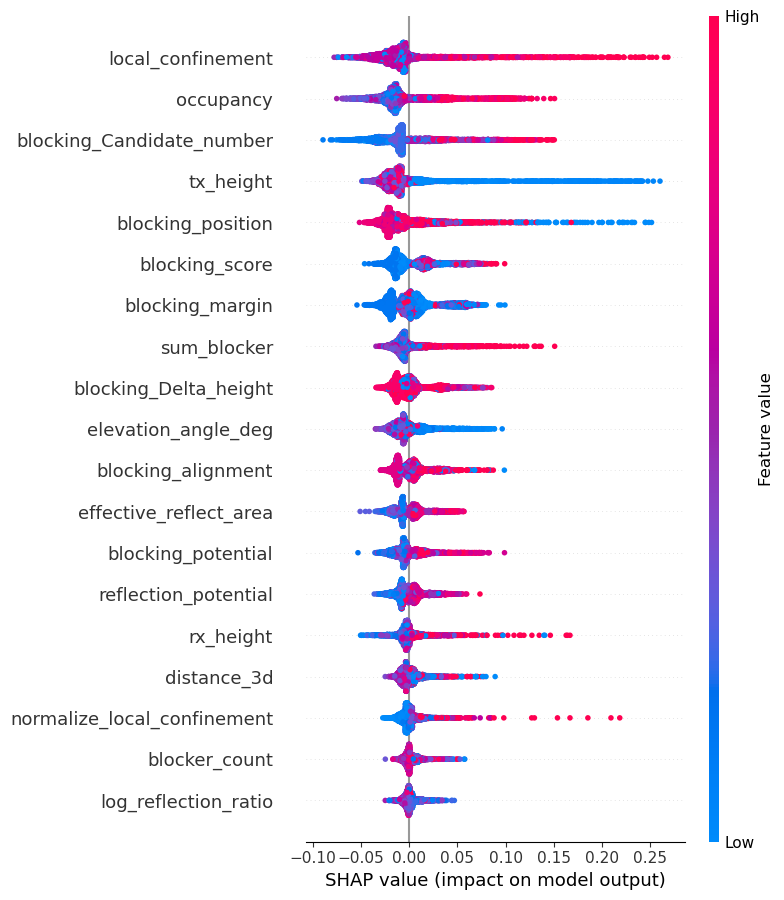

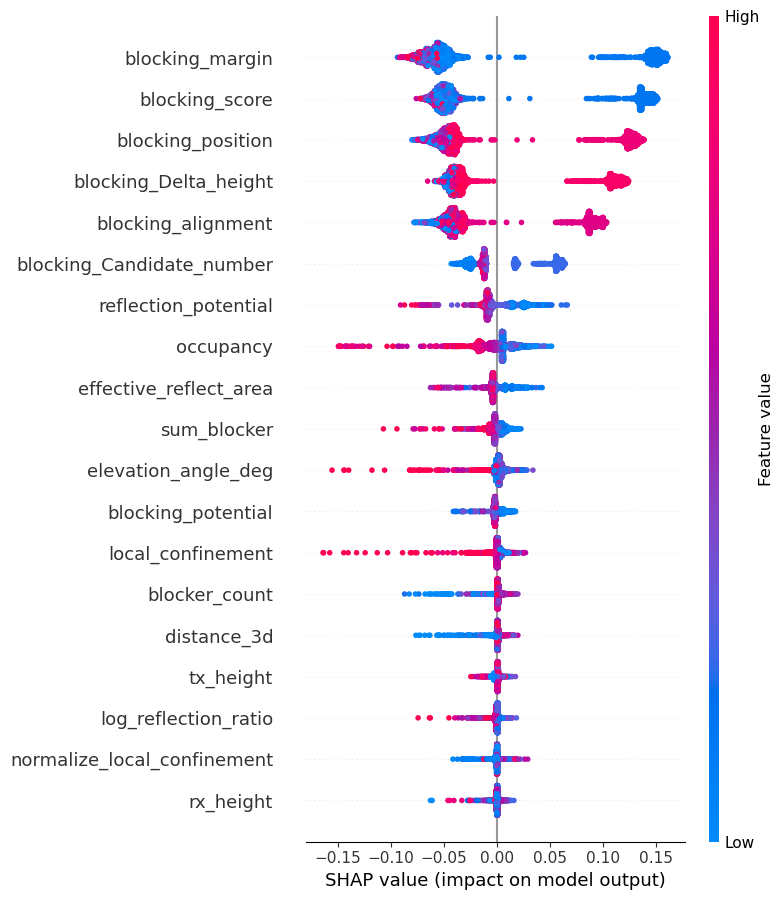

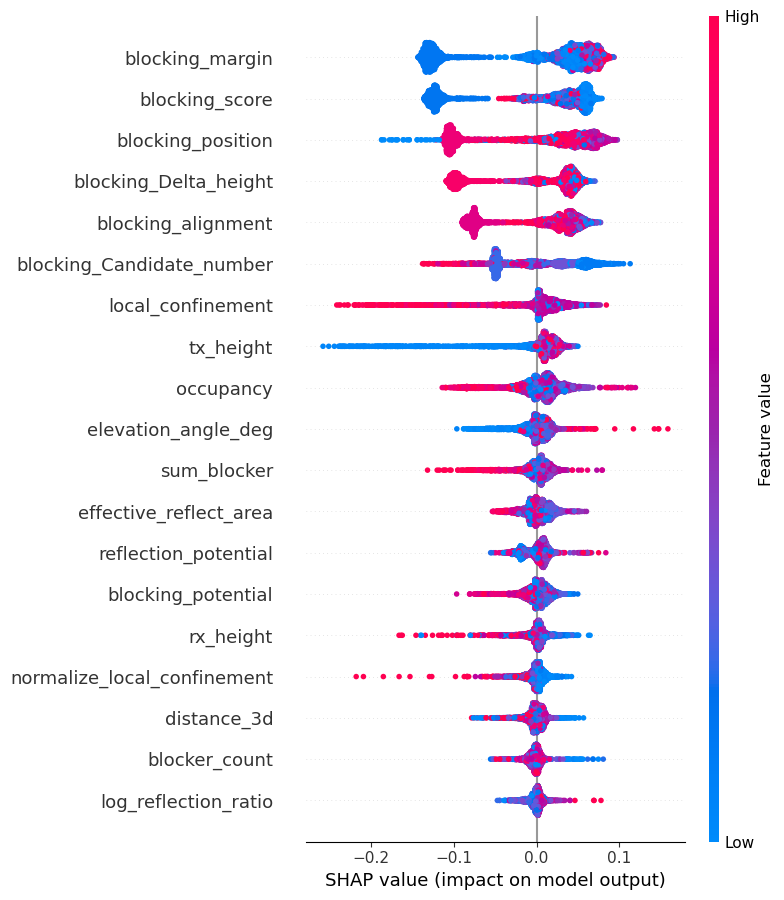

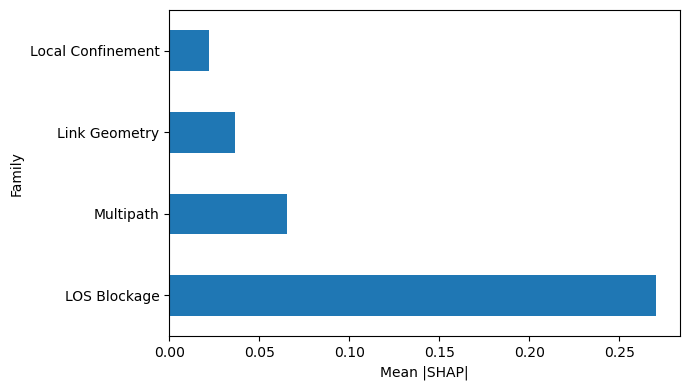

In [7]:



def plot_shap_summary_multiclass(df,feature_cols,feature_family=None,
    label_col="Status",class_names=None,model=None,standardize=False,
    random_state=42,):
    """
    Perform SHAP-based interpretability analysis for multiclass classification.

    The function trains a tree-based classifier, computes SHAP values for each
    propagation class, and evaluates the global and class-specific importance
    of the input descriptors. SHAP summary plots and feature-importance tables
    are saved for each class. When descriptor-family mappings are provided,
    their aggregated SHAP importance is also calculated and visualized.

    Parameters
    ----------
    df : pd.DataFrame
        Input dataframe containing the descriptors and target labels.
    feature_cols : list of str
        Names of the descriptor columns used as model inputs.
    feature_family : dict, optional
        Mapping from descriptor names to descriptor families. If provided,
        SHAP importance is aggregated at the descriptor-family level.
    label_col : str, default="Status"
        Name of the target column containing the propagation classes.
    class_names : list of str, optional
        Names assigned to the output classes. If None, generic class names
        are generated.
    model : sklearn classifier, optional
        Tree-based classification model. If None, a Random Forest classifier
        is used.
    standardize : bool, default=False
        Whether to standardize the input descriptors before model fitting.
    random_state : int, default=42
        Random seed used when initializing the default classifier.

    Returns
    -------
    tuple
        A tuple containing:
        - model : fitted tree-based classifier
        - shap_values : SHAP values for all samples and classes
        - global_importance : DataFrame of global mean absolute SHAP values
        - class_importance : dict of class-specific SHAP importance DataFrames
        - family_importance : Series containing aggregated descriptor-family
          importance, or None if no family mapping is provided.
    """
    data = df[feature_cols + [label_col]].copy()
    X = data[feature_cols]
    y = data[label_col]
    imputer = SimpleImputer(strategy="median")
    X = imputer.fit_transform(X)
    if standardize:
        scaler = StandardScaler()
        X = scaler.fit_transform(X)   
    X = pd.DataFrame(X, columns=feature_cols)
    if model is None:
        model = RandomForestClassifier(n_estimators=300,random_state=random_state,n_jobs=-1,)
    model.fit(X, y)
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X)
    if class_names is None:
        if isinstance(shap_values, list):
            class_names = [f"Class_{i}" for i in range(len(shap_values))]
        else:
            class_names = [f"Class_{i}" for i in range(shap_values.shape[2])]

    if isinstance(shap_values, list):
        mean_abs_shap = np.mean(np.stack([np.abs(s) for s in shap_values], axis=2),axis=(0, 2),)
    else:
        mean_abs_shap = np.mean(np.abs(shap_values),axis=(0, 2),)
    global_importance = pd.DataFrame({
            "Feature": feature_cols,
            "MeanAbsSHAP": mean_abs_shap,}).sort_values("MeanAbsSHAP",ascending=False,)
    print("\nGlobal SHAP Importance")
    print(global_importance)
    global_importance.to_csv(OUTPUT_DIR8,index=False,)
    class_importance = {}
    if isinstance(shap_values, list):
        iterable = enumerate(shap_values)
    else:
        iterable = [(i, shap_values[:, :, i]) for i in range(shap_values.shape[2])]
    for class_idx, class_shap in iterable:
        class_name = class_names[class_idx]
        print(f"\nProcessing {class_name}")
        imp = np.mean(np.abs(class_shap), axis=0)
        df_imp = pd.DataFrame({
                "Feature": feature_cols,
                "MeanAbsSHAP": imp,}).sort_values("MeanAbsSHAP",ascending=False,)
        class_importance[class_name] = df_imp
        df_imp.to_csv(OUTPUT_DIR9 / f"SHAP_{class_name}.csv",index=False,)
        plt.figure(figsize=(8, 6))
        shap.summary_plot(class_shap,X,feature_names=feature_cols,plot_type="dot",show=False,)
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR9 / f"CrossScenario_SHAP_{class_name}.pdf",bbox_inches="tight",)
        plt.savefig(OUTPUT_DIR9 / f"CrossScenario_SHAP_{class_name}.png",dpi=600,bbox_inches="tight",)
        # plt.close()    
    family_importance = None
    if feature_family is not None:
        tmp = global_importance.copy()
        tmp["Family"] = tmp["Feature"].map(feature_family)
        family_importance = (tmp.groupby("Family")["MeanAbsSHAP"].sum().sort_values(ascending=False))
        print("\nDescriptor-family Importance")
        print(family_importance)
        family_importance.to_csv(OUTPUT_DIR9 / "SHAP_Family_Importance.csv")
        plt.figure(figsize=(7,4))
        family_importance.plot.barh()
        plt.xlabel("Mean |SHAP|")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR9 / "SHAP_Family_Importance.pdf",bbox_inches="tight",)
        plt.savefig(OUTPUT_DIR9 / "SHAP_Family_Importance.png",dpi=600,bbox_inches="tight",)
        # plt.close()
    return (model,shap_values,global_importance,class_importance,family_importance,)

def plot_shap_summary_multiclass2(df,feature_cols,label_col="Status",model=None,standardize=False,random_state=42,):
    """
    Generate class-specific SHAP summary plots for multiclass classification.

    A tree-based classifier is trained using the selected descriptors, and
    SHAP values are computed to characterize the contribution of individual
    descriptors to each propagation-class prediction. The function supports
    both list-based and three-dimensional SHAP output formats used by
    different SHAP versions.

    Parameters
    ----------
    df : pd.DataFrame
        Input dataframe containing the descriptors and target labels.
    feature_cols : list of str
        Names of the descriptor columns used as model inputs.
    label_col : str, default="Status"
        Name of the target column containing the propagation classes.
    model : sklearn classifier, optional
        Tree-based classification model. If None, a Random Forest classifier
        is used.
    standardize : bool, default=False
        Whether to standardize the input descriptors before model fitting.
    random_state : int, default=42
        Random seed used when initializing the default classifier.

    Returns
    -------
    tuple
        A tuple containing:
        - model : fitted tree-based classifier
        - shap_values : SHAP values for the predicted classes.
    """
  
    data = df[feature_cols + [label_col]].copy()
    X = data[feature_cols]
    y = data[label_col]
    imputer = SimpleImputer(strategy="median")
    X = imputer.fit_transform(X)
    if standardize:
        scaler = StandardScaler()
        X = scaler.fit_transform(X)
    if model is None:
        model = RandomForestClassifier(n_estimators=300,random_state=random_state,n_jobs=-1,)
    model.fit(X, y)
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X)
    
    if isinstance(shap_values, list):
        for class_idx, class_shap in enumerate(shap_values):
            print(f"\nSHAP summary for class {class_idx}")
            mean_abs_shap = np.mean(np.stack([np.abs(sv) for sv in shap_values], axis=2),axis=(0,2))
            shap.summary_plot(class_shap,X,feature_names=feature_cols,plot_type="dot",show=False)
            fig = plt.gcf()
            fig.tight_layout()
            fig.savefig(OUTPUT_DIR9 / f"CrossScenario_SHAP_Class_{class_idx}.pdf",bbox_inches="tight")            
            fig.savefig(OUTPUT_DIR9 / f"CrossScenario_SHAP_Class_{class_idx}.png",dpi=600,bbox_inches="tight")            
            # plt.close(fig)
    else:
        # Newer SHAP versions may return 3D array:
        # (samples, features, classes)
        n_classes = shap_values.shape[2]
        for class_idx in range(n_classes):
            print(f"\nSHAP summary for class {class_idx}")
            mean_abs_shap = np.mean(np.abs(shap_values), axis=(0,2))
            global_importance = pd.DataFrame({
                "Feature": feature_cols,
                "MeanAbsSHAP": mean_abs_shap
            }).sort_values("MeanAbsSHAP", ascending=False)            
            print(global_importance)            
            global_importance.to_csv("Global_SHAP_Importance.csv",index=False)
            shap.summary_plot(shap_values[:, :, class_idx],
                X,feature_names=feature_cols,plot_type="dot",show=False)
            fig = plt.gcf()
            fig.tight_layout()
            fig.savefig(OUTPUT_DIR9 / f"CrossScenario_SHAP_Class_{class_idx}.pdf",bbox_inches="tight")            
            fig.savefig(OUTPUT_DIR9 / f"CrossScenario_SHAP_Class_{class_idx}.png",dpi=600,bbox_inches="tight")            
            # plt.close(fig)
    return model, shap_values

feature_family = {

    "distance_3d":"Link Geometry",
    "elevation_angle_deg":"Link Geometry",
    "tx_height":"Link Geometry",
    "rx_height":"Link Geometry",

    "blocking_Candidate_number":"LOS Blockage",
    "blocking_score":"LOS Blockage",
    "blocking_position":"LOS Blockage",
    "blocking_alignment":"LOS Blockage",
    "blocking_margin":"LOS Blockage",
    "blocking_Delta_height":"LOS Blockage",

    "blocker_count":"Multipath",
    "sum_blocker":"Multipath",
    "occupancy":"Multipath",
    "blocking_potential":"Multipath",
    "reflection_potential":"Multipath",
    "effective_reflect_area":"Multipath",
    "log_reflection_ratio":"Multipath",

    "local_confinement":"Local Confinement",
    "normalize_local_confinement":"Local Confinement",
}

scenario = scenarios[1] #Seoul
geo_file1 = scenario["Our_geo"]
link_file = scenario["link"]
geo_df = pd.read_csv(geo_file1)
link_df = pd.read_csv(link_file)
df = pd.merge(geo_df,link_df[["TX", "RX", "Status"]],on=["TX", "RX"],how="inner",)


sample_size = 5000

df_sample = (
    df.groupby("Status", group_keys=False)
      .apply(lambda x: x.sample(
          n=min(len(x), int(sample_size * len(x) / len(df))),
          random_state=42))
      .reset_index(drop=True)
)

model, shap_values, global_imp, class_imp, family_imp = \
    plot_shap_summary_multiclass(
        df_sample,
        feature_cols=features1,
        feature_family=feature_family,
        class_names=["Blocked", "LOS", "NLOS"],
    )

# model, shap_values = plot_shap_summary_multiclass2(
#     df_sample,feature_cols=features1,label_col="Status",)